In [1]:
from IPython.display import display, clear_output

from matplotlib import colormaps
import matplotlib.pyplot as pl
import numpy as np
import reddemcee

np.random.seed(1234)

# Autocorrelation Analysis
In this section we will use the 2D gaussian shells again:

The likelihood is given by:

$$ p(\vec{\theta}) = \sum_{i=1}^n \frac{1}{\sqrt{2\pi w^2}} \exp{\left( -\frac{(|\vec{\theta} - \vec{c_i}| - r)^2}{2w^2} \right)} $$

where $n$ are the number of dimensions, $r$ corresponds to the radius, $w$ the width and $\vec{c_i}$ to the constant vectors describing the centre of the peaks.

## Definitions
We define the constants and functions needed:

In [2]:
ndim_ = 2  # n dimensions
r_ = 2.  # radius
w_ = 0.1  # width
hard_limit = 6  # hard search boundary

limits_ = [-hard_limit,  hard_limit]
c1_ = np.zeros(ndim_)
c1_[0] = -3.5
c2_ = np.zeros(ndim_)
c2_[0] = 3.5
const_ = np.log(1. / np.sqrt(2. * np.pi * w_**2))

In [3]:
def logcirc(theta, c):
    # log-likelihood of a single shell
    d = np.sqrt(np.sum((theta - c)**2, axis=-1))  # |theta - c|
    return const_ - (d - r_)**2 / (2. * w_**2)


def loglike(theta):
    # log-likelihood of two shells
    return np.logaddexp(logcirc(theta, c1_), logcirc(theta, c2_))


def logprior(theta):
    # prior for our parameters
    lp = 0.
    for i in range(ndim_):
        if  theta[i] <= limits_[0] or limits_[1] <= theta[i]:
            return -np.inf
    return lp

cmap_plasma = colormaps['plasma']
def running(arr, window_size=10):
    """Calculate running average of the last n values
    for better plot visualisation."""
    averages = np.zeros_like(arr)
    for i in range(arr.shape[0]):
        start_idx = max(0, i - window_size + 1)  # Start of the window (avoid negative index)
        averages[i] = np.mean(arr[start_idx:i + 1], axis=0)  # Average of the last `window_size` points
    return averages

def plot_betas_ratios(sampler, setup):
    bh = sampler.get_betas()
    rh = sampler.get_tsw()

    cmap = colormaps['plasma']
    colors = cmap(np.linspace(0, 0.95, setup[0]))

    fig, axes = pl.subplots(2, 1, figsize=(9, 5), sharex=True)

    for t in range(setup[0]-2):
        # PLOT BETAS
        y_bet = bh[t]
        axes[0].plot(1/y_bet, c=colors[t])

        # PLOT TS_ACCEPTANCE
        x0 = np.arange(setup[2]) * setup[3]
        y_tsw = running(rh[:, t])
        axes[1].plot(x0, y_tsw, alpha=0.75, color=colors[t])

    # plot options
    axes[0].set_ylabel(r"$T$")
    axes[1].set_ylabel(r"$a_{frac}$")

    axes[1].set_xlabel("N Step")

    axes[0].set_xscale('log')
    axes[0].set_yscale('log')

    pl.tight_layout()

## Setup
Here we write the sampler initial conditions:

In [4]:
setup = [10, 100, 500, 2]
ntemps, nwalkers, nsweeps, nsteps = setup
p0 = np.random.uniform(limits_[0], limits_[1], [ntemps, nwalkers, ndim_])

In [5]:
sampler = reddemcee.PTSampler(nwalkers, ndim_, loglike, logprior,
                              ntemps=ntemps,
                              adapt_tau=500,
                              adapt_nu=0.3,
                              adapt_mode='SAR')
    
samples = sampler.run_mcmc(p0, nsweeps, nsteps, progress=True)

100%|██████████| 10000/10000 [00:13<00:00, 756.09it/s]


We take a look at the acceptance fractions:

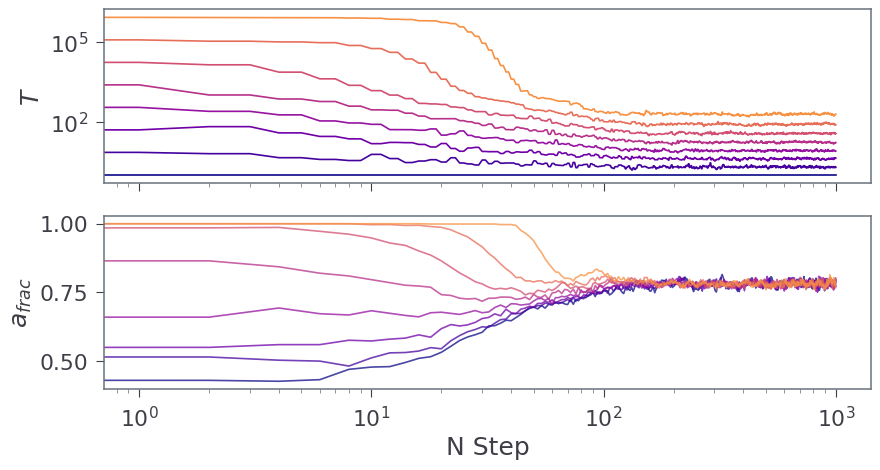

In [6]:
plot_betas_ratios(sampler, setup)

## Auto-stop condition

Auto-stop criteria could be functions of the autocorrelation time, change in temperatures, or acceptance rate convergence across chains.

In this example, we try to make the sampler self-converge by aan autocorrelation time criterion:

We make several "mini-runs", compare the autocorrelation time $\tau$ with the previous mini-run $\tau_{\text{old}}$. If the change in $\tau$ is less than 1\%, we stop the adaptations, and let the chain run for $tol \times \tau$ sweeps.

In [7]:
setup = [16, 128, 1024, 1]
ntemps, nwalkers, nsweeps, nsteps = setup
p0 = np.random.uniform(limits_[0], limits_[1], [ntemps, nwalkers, ndim_])

sampler = reddemcee.PTSampler(nwalkers, ndim_, loglike, logprior,
                              ntemps=ntemps,
                              adapt_tau=256,
                              adapt_nu=0.64,
                              adapt_mode='SAR')

In [8]:
burnin0 = 100  # length of this 'minichain'
burnin0_runs = 20  # maximum of mini-chains to run


state = p0
old_tau = np.inf
ac = np.empty(burnin0_runs)
tol_warn = 0  # gets a message if chain is shorter than this
tol0 = 50  # times tau should be shorter than the chain
stop_percent = 0.01


for i in range(burnin0_runs):
    state = sampler.run_mcmc(state, burnin0, nsteps, progress=True)
    tau0 = sampler.get_autocorr_time(quiet=True, tol=tol_warn)[0]
    clear_output(wait=True)
    ac[i] = np.mean(tau0)

    niter = sampler.iteration
    converged = np.all(tau0 * tol0 < niter)
    converged &= np.all(np.abs(old_tau - tau0) / tau0 < stop_percent)

    display(f'Memory free initial position: {i+1}/{burnin0_runs}',
            f'ACi     : {ac[i]}',
            f'tau     : {tau0}',
            f'niter   : {niter}',
            f'converge: {converged}')

    if converged:
        print(f'CONVERGED! ')
        break        
      
    old_tau = tau0

auto_nsweeps = int((max(tau0) * tol0))

sampler.select_adjustment('NONE')
samples = sampler.run_mcmc(state, auto_nsweeps, nsteps,
                           progress=True)

total_sweeps = sampler.iteration
burnin_nsweeps = total_sweeps - auto_nsweeps

'Memory free initial position: 13/20'

'ACi     : 17.64003273717661'

'tau     : [18.62837985 16.65168563]'

'niter   : 1300'

'converge: True'

CONVERGED! 


100%|██████████| 14896/14896 [00:24<00:00, 619.73it/s]


### Temperatures Visualisation

We plot the temperature adaptation and the swap rates to observe our algorithm in action:

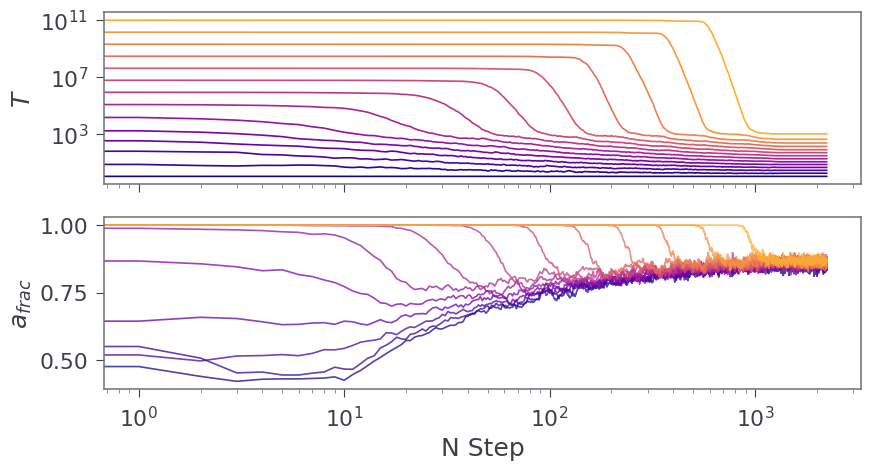

In [9]:
def plot_auto_betas_ratios(sampler, setup):
    bh = sampler.get_betas()
    rh = sampler.get_tsw()

    cmap = colormaps['plasma']
    colors = cmap(np.linspace(0, 0.95, setup[0]))

    fig, axes = pl.subplots(2, 1, figsize=(9, 5), sharex=True)

    for t in range(setup[0]-2):
        # PLOT BETAS
        y_bet = bh[t]
        axes[0].plot(1/y_bet, c=colors[t])

        # PLOT TS_ACCEPTANCE
        y_tsw = running(rh[:, t])
        axes[1].plot(y_tsw, alpha=0.75, color=colors[t])

    # plot options
    axes[0].set_ylabel(r"$T$")
    axes[1].set_ylabel(r"$a_{frac}$")

    axes[1].set_xlabel("N Step")

    axes[0].set_xscale('log')
    axes[0].set_yscale('log')

    pl.tight_layout()

plot_auto_betas_ratios(sampler, [ntemps, nwalkers, total_sweeps, nsteps])

### Results sanity check

We check the evidence values and compare with the analitical result:
$$Z = -1.75$$

In [10]:
Z0, Zerr0 = sampler.get_evidence_ti(discard=burnin_nsweeps)
Z1, Zerr1 = sampler.get_evidence_ss(discard=burnin_nsweeps)
Z2, Zerr2 = sampler.get_evidence_hybrid(discard=burnin_nsweeps)

print(f'Evidence TI: {Z0:.4f} +- {Zerr0:.4f}')
print(f'Evidence SS: {Z1:.4f} +- {Zerr1:.4f}')
print(f'Evidence Hy: {Z2:.4f} +- {Zerr2:.4f}')

Evidence TI: -1.7659 +- 0.0312
Evidence SS: -1.7538 +- 0.0072
Evidence Hy: -1.7613 +- 0.0277
